# Fire-Sale Price Audit
## tl;dr
Un solo precio terminal no agota el conjunto de equilibrios. Este componente S2
enumera regímenes de liquidación de un activo con demanda inversa lineal y piso.
La multiplicidad no es una contribución teórica nueva: el aporte es el censo
reproducible de raíces, los controles de tangencia y la comparación con el repo.
El programa Sovereign–Bank Strategic Nexus sigue **S2 parcial**: no hay un gobierno
estratégico ni estimación de precios soberanos o de probabilidad de crisis.

## Context & Methods
### Pregunta, alternativas y umbrales
¿Cuánto riesgo de selección oculta el stress a precio fijo o una iteración desde
el precio fundamental? H1: el fixture de dos bancos debe producir exactamente
precios .05, .2 y .8 con error absoluto ≤1e-10; la iteración superior omite dos.
H2: con financiación total .3125 existe una raíz doble en .5 que debe recuperarse.
Un contraejemplo invalida la generalización del resultado: no basta dibujar una
curva que parezca converger. Los controles sin impacto o con caja suficiente
deben recuperar únicamente q=1. Las barreras son convenciones experimentales,
no significación estadística ni estimación causal.

### Key Assumptions y mecanismo económico
Cada banco i tiene caja c_i, deuda vencida D_i y s_i unidades de un activo común.
Toda la deuda es externa; los pagos interbancarios se **excluyen** en este módulo.
El activo puede representar una cartera soberana homogénea, pero no se modelan
default soberano, plazo ni riesgo fiscal. Sin ventas cortas, compras bancarias,
colateral, crédito de emergencia ni costos de quiebra. Agentes precio-aceptantes
obedecen una regla mínima, no resuelven un juego de liquidación.
$$d_i=(D_i-c_i)^+,\quad \gamma_i(q)=\min(s_i,d_i/q),$$
$$F(q)=\max(q_{min},q_0-a\sum_i\gamma_i(q)),\quad q=F(q).$$
Todas las unidades se venden al mismo precio uniforme final q. No son ingresos
integrados bajo una curva marginal de ejecución. El piso supone demanda externa
perfectamente elástica allí, no un rescate gratuito demostrado factible.
La misma ecuación puede representar ventas simultáneas, pero la iteración de
Picard no es una dinámica económica estimada.

In [1]:
import sys,json,csv
from pathlib import Path
from dataclasses import replace,asdict
sys.path.insert(0,str(Path('src').resolve()))
from market import Market,equilibria,iterate,balance,update
m=Market((0.,0.),(.1,.1),(1.,1.),.8)
for r in equilibria(m): print(asdict(r),balance(m,r.price))

{'price': 0.05, 'residual': 0.0, 'slope_left': 0.0, 'slope_right': 0.0, 'stability': 'stable'} {'price': 0.05, 'sales': 2.0, 'paid': 0.1, 'unpaid': 0.1, 'equity': 0.0, 'marked_loss': 1.9, 'identity_error': 0.0}
{'price': 0.2, 'residual': 5.551115123125783e-17, 'slope_left': 4.0, 'slope_right': 4.0, 'stability': 'unstable'} {'price': 0.2, 'sales': 1.0, 'paid': 0.2, 'unpaid': 0.0, 'equity': 0.2, 'marked_loss': 1.6, 'identity_error': 0.0}
{'price': 0.8, 'residual': 0.0, 'slope_left': 0.25, 'slope_right': 0.25, 'stability': 'stable'} {'price': 0.8, 'sales': 0.25, 'paid': 0.2, 'unpaid': 0.0, 'equity': 1.4000000000000001, 'marked_loss': 0.3999999999999999, 'identity_error': 0.0}


### Formulación por tramos y alcance de la enumeración
Los quiebres ocurren en q=d_i/s_i para s_i>0. En cada intervalo el conjunto S
de bancos que vende toda su cartera es fijo. Definiendo
$$A=\sum_{i\in S}s_i,\quad B=\sum_{i\notin S}d_i,$$
la condición interior equivale a
$$q^2-(q_0-a A)q+a B=0.$$
Se evalúan ambos candidatos de cada cuadrática, se verifica pertenencia al tramo,
se añade el piso solo si F(piso)=piso y se eliminan duplicados. Esa reducción
algebraica es elemental y válida para **este** modelo; no prueba exhaustividad
del modelo multiactivo de la literatura. El código calcula signos del
discriminante con Fraction de los strings decimales y raíces con Decimal(64).
Los precios publicados son float. No hay redondeo dirigido ni certificación
formal; se rechazan raíces distintas con separación <1e-10.
El costo implementado O(n²) prioriza claridad y no es un solver industrial.

In [2]:
roots=equilibria(m)
print('Raíces enumeradas:',[r.price for r in roots])
print('Picard superior e iteraciones:',iterate(m,1.))
print('Picard inferior:',iterate(m,m.floor))
print('Una sola actualización:',update(m,1.))
print('Baseline precio fijo:',balance(m,1.))
assert [round(r.price,10) for r in roots]==[.05,.2,.8]

Raíces enumeradas: [0.05, 0.2, 0.8]
Picard superior e iteraciones: (0.8000000000001364, 20)
Picard inferior: (0.05, 1)
Una sola actualización: 0.84
Baseline precio fijo: {'price': 1.0, 'sales': 0.2, 'paid': 0.2, 'unpaid': 0.0, 'equity': 1.8, 'marked_loss': 0.0, 'identity_error': 0.0}


### Estabilidad, selección y refutación de unicidad
En un tramo sin piso, F'(q)=aB/q². La etiqueta estable se refiere únicamente a
atracción local de esa iteración (pendientes de ambos lados <1), no estabilidad
macroeconómica, bienestar ni selección racional de equilibrio. En el fixture,
las pendientes son 0,4,.25. Los inicios extremos encuentran las dos soluciones
estables, pero no la inestable. Una malla+Brent puede hallar las tres si las
separa; tampoco garantiza ver tangencias o pares más cercanos que su malla.
Para bancos idénticos no saturados, B es la necesidad total de fondos:
$$\Delta=q_0^2-4aB.$$
Con a=.8, q0=1 el pliegue aparece en B=.3125, q=.5. Esto es una identidad
analítica del ejemplo, no una bifurcación empíricamente identificada.

In [3]:
fold=replace(m,debt=(.15625,.15625))
for delta in [-1e-8,0,1e-8]:
 case=replace(fold,debt=(.15625+delta,)*2)
 print('Cambio por banco:',delta,'precios:',[r.price for r in equilibria(case)])
print(Path('results/ablations.csv').read_text())

Cambio por banco: -1e-08 precios: [0.05, 0.4998735088935933, 0.5001264911064067]
Cambio por banco: 0 precios: [0.05, 0.5]
Cambio por banco: 1e-08 precios: [0.05]
case,grid_size,reference_count,grid_count,missed,reference,grid
main,101,3,3,0,"[0.05, 0.2, 0.8]","[0.05, 0.2, 0.8]"
main,1001,3,3,0,"[0.05, 0.2, 0.8]","[0.05, 0.2, 0.8]"
zero_impact,101,1,1,0,[1.0],[1.0]
zero_impact,1001,1,1,0,[1.0],[1.0]
cash_covers_debt,101,1,1,0,[1.0],[1.0]
cash_covers_debt,1001,1,1,0,[1.0],[1.0]
fold,101,2,1,1,"[0.05, 0.5]",[0.05]
fold,1001,2,1,1,"[0.05, 0.5]",[0.05]
near_fold,101,3,1,2,"[0.05, 0.4998735088935933, 0.5001264911064067]",[0.05]
near_fold,1001,3,1,2,"[0.05, 0.4998735088935933, 0.5001264911064067]",[0.05]
higher_floor,101,1,1,0,[0.8],[0.8]
higher_floor,1001,1,1,0,[0.8],[0.8]



## Data y contabilidad
Todo es sintético, seed20261019. No se descargan balances ni datos de mercado.
No hay identificación de a, q0 ni el piso: son supuestos. No se usa bootstrap
para disfrazar repetición de un escenario determinista como incertidumbre.
$$p_i=\min(D_i,c_i+q\gamma_i),\quad
 E_i=c_i+q\gamma_i-p_i+q(s_i-\gamma_i).$$
De aquí, sum(c_i+q s_i)=sum(p_i+E_i). El impago son promesas contractuales
incumplidas; la pérdida marcada es (q0-q)sum(s_i). No son lo mismo y ninguna
de las dos equivale por sí sola a pérdida social: faltan compradores, utilidad
y valor de tenencia fuera del sector bancario.

In [4]:
for r in roots:
 b=balance(m,r.price)
 print('q,ventas,pago,impago,pérdida marcada,identidad:',[b[k] for k in ['price','sales','paid','unpaid','marked_loss','identity_error']])
print('Reducción al EN anterior (sin aristas interbancarias):')
print(Path('results/repo_regression.csv').read_text())

q,ventas,pago,impago,pérdida marcada,identidad: [0.05, 2.0, 0.1, 0.1, 1.9, 0.0]
q,ventas,pago,impago,pérdida marcada,identidad: [0.2, 1.0, 0.2, 0.0, 1.6, 0.0]
q,ventas,pago,impago,pérdida marcada,identidad: [0.8, 0.25, 0.2, 0.0, 0.3999999999999999, 0.0]
Reducción al EN anterior (sin aristas interbancarias):
price,en_paid,local_paid,difference
0.05,0.10000000000000009,0.1,8.326672684688674e-17
0.2,0.2,0.2,0.0
0.8,0.2,0.2,0.0
1.0,0.2,0.2,0.0



## Results
La figura compara F(q) con la diagonal y muestra todas las ramas de equilibrio
en el barrido de fondos. Son escenarios, no intervalos de confianza. El piso
produce una rama baja cuya existencia depende del supuesto de demanda externa:
subirlo a .3 elimina la solución de default del ejemplo y deja solo .8. Esto
no prueba que apoyar precios sea gratis o mejore bienestar.

case,enum_count,grid_count,max_price_error
0,1,1,0.0
1,3,3,3.3394953469212396e-12
2,1,1,0.0
3,1,1,0.0
4,3,3,1.9133583606389948e-12
5,3,3,2.1259660698547123e-12
6,3,3,1.580957587066223e-12
7,3,3,1.6837642391465124e-12
8,1,1,0.0
9,1,1,0.0
10,1,1,3.277156324088537e-12
11,3,3,4.142242104876459e-12
12,3,3,3.1848967907421866e-12
13,1,1,3.4269254101104707e-12
14,1,1,0.0
15,3,3,2.0512480602974392e-12
16,1,1,1.7326140522300193e-12
17,3,3,3.3995584125534606e-12
18,1,1,1.804445481923267e-12
19,3,3,3.286593219797851e-12
20,3,3,3.286593219797851e-12
21,3,3,3.162137218737371e-12
22,3,3,3.264832848515198e-12
23,3,3,2.608940841142271e-12
24,3,3,3.277156324088537e-12
25,3,3,3.86246590267092e-12
26,1,1,0.0
27,3,3,3.5409453147394743e-12
28,3,3,1.6837642391465124e-12
29,1,1,0.0
30,1,1,0.0
31,1,1,0.0
32,3,3,4.569344902449757e-12
33,3,3,0.0
34,1,1,0.0
35,1,1,0.0
36,1,1,8.615330671091215e-14
37,3,3,3.1848967907421866e-12
38,3,3,4.142242104876459e-12
39,1,1,0.0



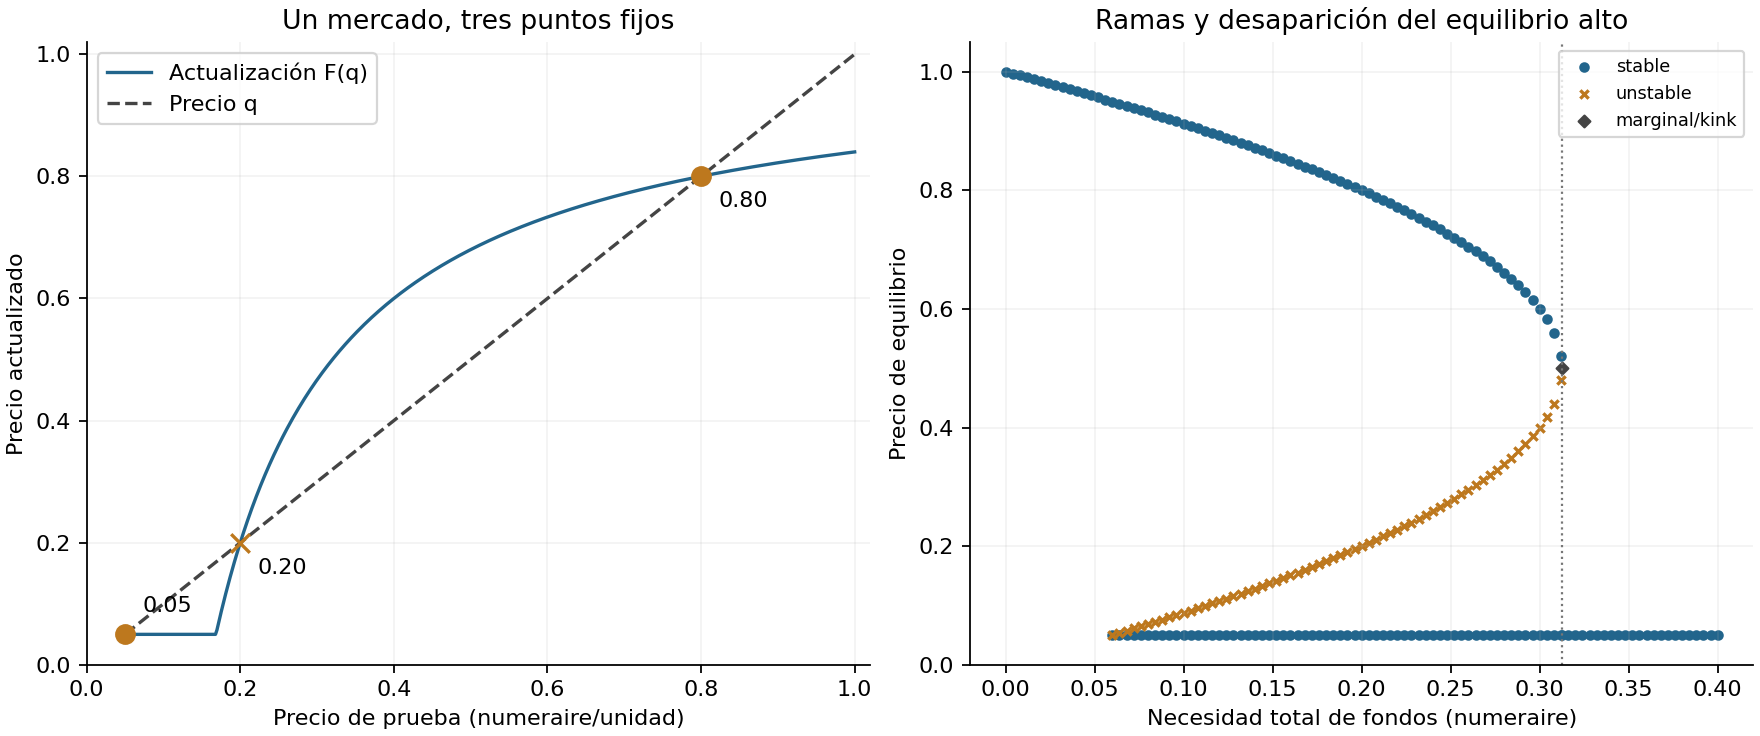

In [5]:
from IPython.display import Image,display
display(Image(filename='results/comparison.png'))
print(Path('results/numerical_crosscheck.csv').read_text())

### Benchmarks y controles negativos
Se mide pared y pico de asignaciones Python con tracemalloc, no RSS ni memoria
nativa total. Tres repeticiones, n=8,32,128 con exposiciones agregadas casi
constantes y heterogeneidad por banco. La enumeración busca **todas** las raíces;
Picard busca una: no se atribuye una mejora de velocidad por resolver problemas
distintos. Malla101+Brent es un baseline numérico independiente, no la
implementación completa de Feinstein. El contraste a malla4001 tiene 40 casos
aleatorios no degenerados y no demuestra exhaustividad para todos los parámetros.

In [6]:
rows=list(csv.DictReader(Path('results/costs.csv').open()))
for row in rows:
 if row['n']=='128': print(row)
print(Path('results/coverage.txt').read_text())
print(json.loads(Path('results/metadata.json').read_text()))

{'n': '128', 'method': 'rational_regimes', 'repeat': '0', 'seconds': '0.027234086000021307', 'python_peak_bytes': '50020', 'roots_recovered': '3', 'reference_roots': '3', 'max_residual': '1.3877787807814457e-17'}
{'n': '128', 'method': 'rational_regimes', 'repeat': '1', 'seconds': '0.028029987999957484', 'python_peak_bytes': '50020', 'roots_recovered': '3', 'reference_roots': '3', 'max_residual': '1.3877787807814457e-17'}
{'n': '128', 'method': 'rational_regimes', 'repeat': '2', 'seconds': '0.02880692199994428', 'python_peak_bytes': '50020', 'roots_recovered': '3', 'reference_roots': '3', 'max_residual': '1.3877787807814457e-17'}
{'n': '128', 'method': 'upper_iteration', 'repeat': '0', 'seconds': '0.0027377959999057566', 'python_peak_bytes': '9008', 'roots_recovered': '1', 'reference_roots': '3', 'max_residual': '9.114931032172535e-14'}
{'n': '128', 'method': 'upper_iteration', 'repeat': '1', 'seconds': '0.0028014209999582818', 'python_peak_bytes': '9008', 'roots_recovered': '1', 'refe

## Takeaways, fallos y límites
Fallos de desarrollo corregidos: el primer benchmark intentó pasar la clave
price dos veces a dict; la primera invocación del pipeline se lanzó antes de
crear benchmarks. Se conserva el resultado final ejecutado, no se declaran
aquellos intentos como éxitos. Fallos metodológicos intencionales: una única
iteración no es equilibrio, un punto fijo no prueba unicidad y cambios de signo
no detectan todas las raíces dobles. Límites del solver: precisión finita,
complejidad cuadrática y piso positivo obligatorio. No se validó n>128.
La combinación simultánea con red EN, colateral y un gobierno estratégico sigue
pendiente; la regresión EN solo comprueba la reducción sin enlaces.
Ver informe.md, referencias.bib y results/search_log.md para fuentes consultadas,
bloqueos y límites de la revisión. No se afirma prioridad científica ni S3.